In [1]:
import matplotlib.pyplot as plt
import numpy as np
from simsopt.mhd import Vmec

from spectre import SPECTRE, SPECTREout
from spectre.converters import simsvmec2spectre

%matplotlib inline

## Load VMEC equilibria

Two sources can be used:
- `input.<name>` — VMEC input file. Contains profile info and the plasma boundary only.
- `wout_<name>.nc` — VMEC output file. Contains interfaces of the solved equilibrium. Generate this by running VMEC or VMEC++ on the input file. Uncomment the lines if you have generated this file. 

In [2]:
vmec_in  = Vmec("input.iota")


 - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - -
  VMEC OUTPUT FILES ALREADY EXIST: OVERWRITING THEM ...
  SEQ =    1 TIME SLICE  0.0000E+00
  PROCESSING INPUT.iota
  THIS IS PARVMEC (PARALLEL VMEC), VERSION 9.0
  Lambda: Full Radial Mesh. L-Force: hybrid full/half.

  COMPUTER:    OS:    RELEASE:   DATE = Jun 24,2026  TIME = 12:31:25


## Convert from `input.iota` (no interface guesses)

`linitialize=1` — SPECTRE linearly interpolates the initial interface geometry from the boundary.

In [3]:
tfluxes = np.linspace(0.0, 1.0, 6, endpoint=True)[1:]  # 5 volumes

params_from_input = simsvmec2spectre(vmec_in, tfluxes=tfluxes, mpol=6, ntor=5, interface_guess=None)

The input without good interface guesses interpolates from the boundary. It has self-intersections and will not work. 

readin :            : 
readin :       0.04 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  0 ; phiedge=  1.381320248746202E+02 ; curtor=  0.000000000000000E+00 ; curpol=  0.000000000000000E+00 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  2 ; Nvol=  5 ; Mvol=  5 ; Mpol=  6 ; Ntor=  5 
readin :            : pscale=  1.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  1 ; mupf: tol,its=  1.00E-14,   8 
readin :            : Lrad = 10,10,10,10,10,
readin :            : 
readin :       0.04 : Linitialize=  1 ;LautoinitBn=  1 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : 
readin :            : 
readin :            : escale=  0.00000E+00 ; opsilon=  1.00000E+00 ; pcondense=  2.000 ; epsilon=  0.00000E+00 ; wpoloidal        = 1.0000 ; upsilon=  1.00000E+00 
readin :            : mfreeits=   0 ; gBntol=  1.00000E-06 ; gBnbld=  6.66000E-01 
rea

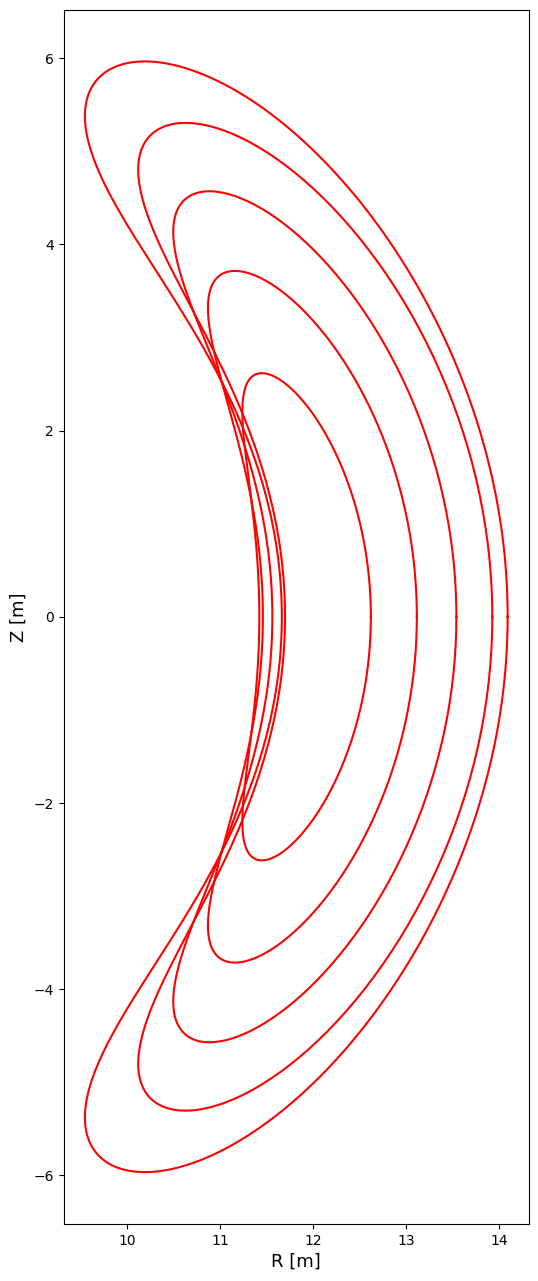

In [4]:
spectre_input = SPECTRE.from_input_params(params_from_input)
out_from_input = spectre_input.create_spectreout()
out_from_input.plot_infaces()

## Create interface guesses using `map2disc`

You can greate a better initial start by computing the interfaces using `Map2Disc`, which ensures that the interfaces contain no self-intersections.`Map2Disc` routines can take a bit longer for high resolution interfaces. 

In [5]:
params_map = simsvmec2spectre(vmec_in, tfluxes=tfluxes, mpol=6, ntor=5, plot=False, interface_guess='map2disc')

readin :            : 
readin :      13.99 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  0 ; phiedge=  1.381320248746202E+02 ; curtor=  0.000000000000000E+00 ; curpol=  0.000000000000000E+00 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  2 ; Nvol=  5 ; Mvol=  5 ; Mpol=  6 ; Ntor=  5 
readin :            : pscale=  1.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  1 ; mupf: tol,its=  1.00E-14,   8 
readin :            : Lrad = 10,10,10,10,10,
readin :            : 
readin :      13.99 : Linitialize=  0 ;LautoinitBn=  1 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : 
readin :            : 
readin :            : escale=  0.00000E+00 ; opsilon=  1.00000E+00 ; pcondense=  2.000 ; epsilon=  0.00000E+00 ; wpoloidal        = 1.0000 ; upsilon=  1.00000E+00 
readin :            : mfreeits=   0 ; gBntol=  1.00000E-06 ; gBnbld=  6.66000E-01 
rea

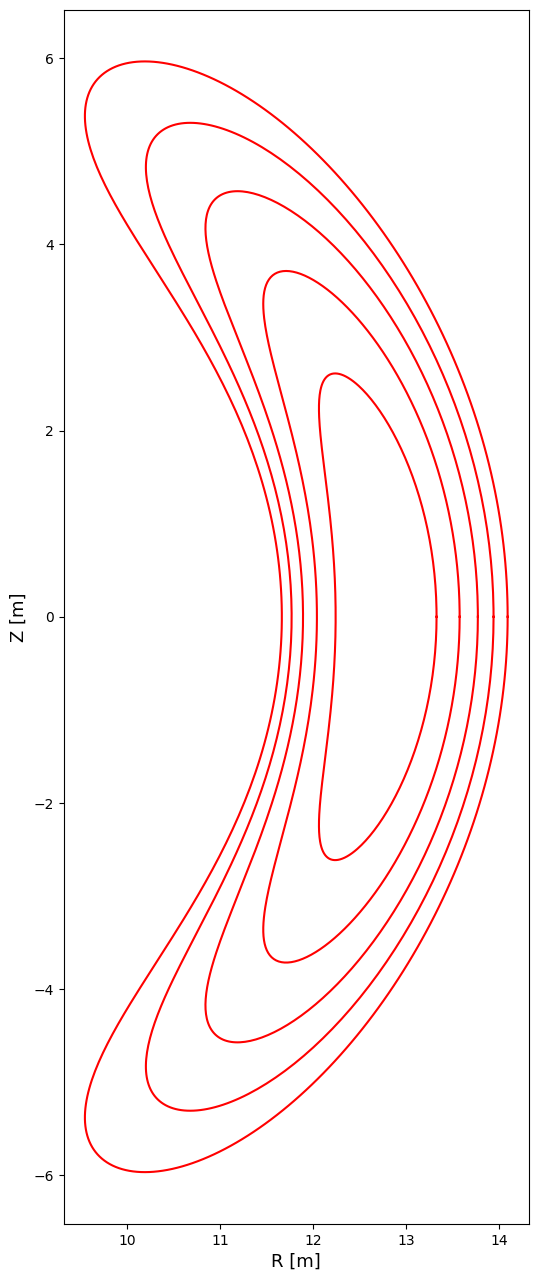

In [6]:
spectre_map = SPECTRE.from_input_params(params_map)
out_from_map = spectre_map.create_spectreout()
out_from_map.plot_infaces()

## Convert from `wout_iota.nc` (with interface guesses)

If we have a `simsopt.mhd.Vmec` object generated from a wout file (run vmec on input.iota to generate this), we can directly read the interfaces computed there, giving us an even closer approximation of the initial equilibrium.  

You can also call vmec_in.run(), and the wout info will be present in the vmec_in object. 

Uncomment the following code once you have generated the Wout file to generate interfaces from it. 

In [7]:
#vmec_wout = Vmec("wout_iota.nc")
#params_from_wout = simsvmec2spectre(vmec_wout, tfluxes=tfluxes, mpol=6, ntor=5, plot=False, interface_guess='wout')


readin :            : 
readin :      14.12 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  0 ; phiedge=  1.381320248746204E+02 ; curtor=  0.000000000000000E+00 ; curpol=  0.000000000000000E+00 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  2 ; Nvol=  5 ; Mvol=  5 ; Mpol=  6 ; Ntor=  5 
readin :            : pscale=  1.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  1 ; mupf: tol,its=  1.00E-14,   8 
readin :            : Lrad = 10,10,10,10,10,
readin :            : 
readin :      14.12 : Linitialize=  0 ;LautoinitBn=  1 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : 
readin :            : 
readin :            : escale=  0.00000E+00 ; opsilon=  1.00000E+00 ; pcondense=  2.000 ; epsilon=  0.00000E+00 ; wpoloidal        = 1.0000 ; upsilon=  1.00000E+00 
readin :            : mfreeits=   0 ; gBntol=  1.00000E-06 ; gBnbld=  6.66000E-01 
rea

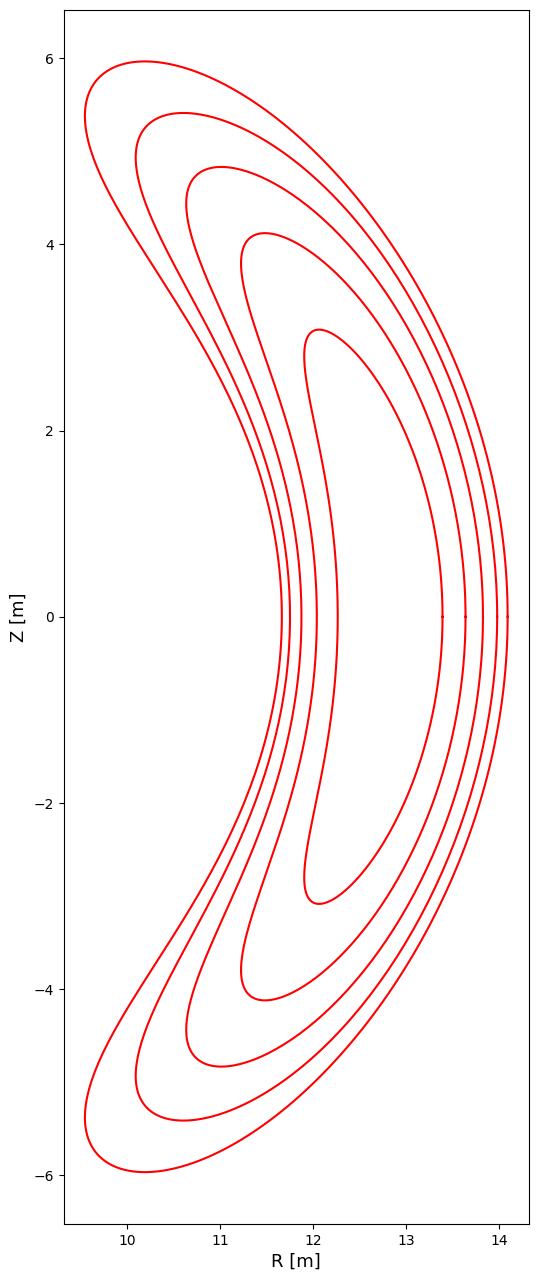

In [8]:
#spectre_wout = SPECTRE.from_input_params(params_from_wout)
#out_from_wout = spectre_wout.create_spectreout()
#out_from_wout.plot_infaces()